# Task 1 (extra) - Undersampling with ENN (Edited Nearest Neighbours)
Extra part of Task 1. The main work (RandomUnderSampler) is in `01_undersampling`.

AI use: Claude was used to understand the topic, little guidance and some code was taken from it.

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from imblearn.under_sampling import EditedNearestNeighbours
from sklearn.preprocessing import StandardScaler

## Data
ENN uses distances between rows, so it needs all-numeric data. I use the numeric (one-hot encoded) version of the adult dataset. The target `income` is 1 for `>50K` and 0 for `<=50K`.

In [5]:
df = pd.read_csv("../../../Datasets/cleaned_adult_data.csv")   

X = df.drop(columns="income")
y = df["income"]

print("Rows before:", len(df))
print(y.value_counts())

Rows before: 30139
income
<=50K    22633
>50K      7506
Name: count, dtype: int64


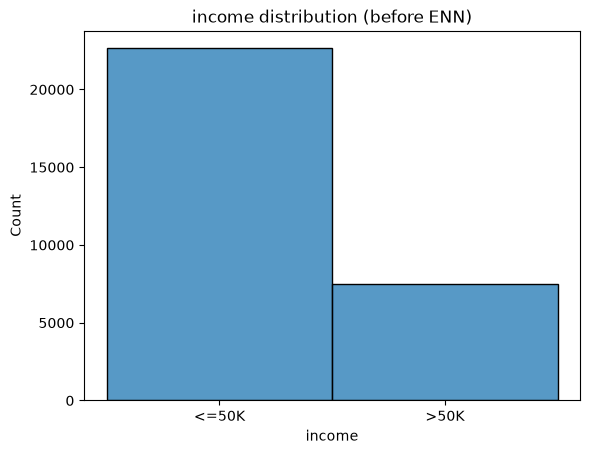

In [6]:
sns.histplot(df, x="income")
plt.title("income distribution (before ENN)")
plt.show()

In [7]:
# ENN uses distances, so big numbers (capital.gain) would dominate without scaling
scale_cols = ["age", "education.num", "hours.per.week", "capital.gain", "capital.loss"]
X_scaled = X.copy()
X_scaled[scale_cols] = StandardScaler().fit_transform(X[scale_cols])

In [ ]:
enn = EditedNearestNeighbours()          
X_enn, y_enn = enn.fit_resample(X_scaled, y)

df_enn = X_enn.copy()
df_enn["income"] = y_enn

print("Rows after:", len(df_enn))
print(df_enn["income"].value_counts())

Rows after: 24222
income
<=50K    16716
>50K      7506
Name: count, dtype: int64


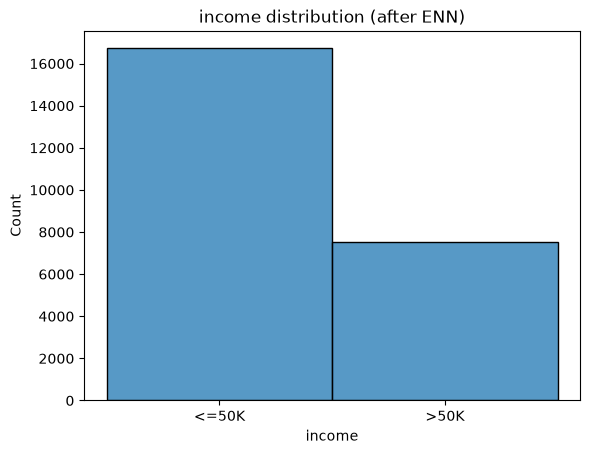

In [9]:
sns.histplot(df_enn, x="income")
plt.title("income distribution (after ENN)")
plt.show()

Ask claude to generate the code for better comparision

In [12]:
df_enn_original = df.iloc[enn.sample_indices_]

compare_cols = ["age", "education.num", "hours.per.week", "capital.gain", "capital.loss"]

comparison = pd.DataFrame({
    "before": df[compare_cols].mean(),
    "after (ENN)": df_enn_original[compare_cols].mean()
}).round(2)

print(comparison)
print()
print("Share of >50K before:", round((y == ">50K").mean() * 100, 1), "%")
print("Share of >50K after: ", round((df_enn_original["income"] == ">50K").mean() * 100, 1), "%")

                 before  after (ENN)
age               38.44        37.46
education.num     10.12        10.05
hours.per.week    40.93        40.13
capital.gain    1092.84      1293.41
capital.loss      88.44        85.76

Share of >50K before: 24.9 %
Share of >50K after:  31.0 %


## Conclusion
- Rows before: 30,139, after: 24222  (about 5,900 removed, roughly 20%).
- Class split: >50K went from 24.9% to 31.0%. ENN only removed <=50K rows, so all 7,506 >50K rows were kept.
- ENN removes majority-class rows that sit among minority-class neighbours, so it cleans the boundary between the classes instead of forcing an even split. It therefore did not balance the data fully, but it improved the balance a little.
- The statistics stayed similar: mean age 38.4 > 37.5, education 10.12 > 10.05, hours per week 40.9 > 40.1. Capital gain rose from 1,093 to 1,293, probably because the share of >50K people increased. Compared with random undersampling (even split: capital gain 2,045, age 40.3), ENN distorted the data much less.
- It works best when the classes overlap or there is noise at the boundary and the dataset is large enough to lose some rows.